In [1]:
import xarray as xr
import numpy as np
import xesmf as xe
from regional_mom6 import regridding as rgd

In [53]:
river_nutrients = xr.open_dataset("/glade/work/mlevy/cesm_inputdata/work/river_nutrients.GNEWS_GNM.glofas.20250819.nc")
river_nutrients = river_nutrients.assign_coords(
    lon=((river_nutrients.lon + 360) % 360)
)
river_nutrients
rn_sorted = river_nutrients.sortby("lon")


In [3]:
mapping_file = xr.open_dataset("~/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/glofas_nwa12_nn_lon_west.nc")
mapping_file

<xarray.Dataset>
Dimensions:        (n_a: 5400000, nv_a: 4, src_grid_rank: 2, nj_a: 1500,
                    ni_a: 3600, n_b: 577200, nv_b: 4, dst_grid_rank: 2,
                    nj_b: 780, ni_b: 740, n_s: 331968)
Coordinates:
  * nj_a           (nj_a) int32 1 2 3 4 5 6 7 ... 1495 1496 1497 1498 1499 1500
  * ni_a           (ni_a) int32 1 2 3 4 5 6 7 ... 3595 3596 3597 3598 3599 3600
  * nj_b           (nj_b) int32 1 2 3 4 5 6 7 8 ... 774 775 776 777 778 779 780
  * ni_b           (ni_b) int32 1 2 3 4 5 6 7 8 ... 734 735 736 737 738 739 740
Dimensions without coordinates: n_a, nv_a, src_grid_rank, n_b, nv_b,
                                dst_grid_rank, n_s
Data variables: (12/19)
    xc_a           (n_a) float64 ...
    yc_a           (n_a) float64 ...
    xv_a           (n_a, nv_a) float64 ...
    yv_a           (n_a, nv_a) float64 ...
    mask_a         (n_a) int32 ...
    area_a         (n_a) float64 ...
    ...             ...
    area_b         (n_b) float64 ...
    frac_b         (n_b) float64 ...
    dst_grid_dims  (dst_grid_rank) int32 ...
    S              (n_s) float64 ...
    col            (n_s) int32 ...
    row            (n_s) int32 ...
Attributes:
    title:        mom6_bathy mapping generation
    history:      generated by mom6_bathy
    conventions:  NCAR-CCSM

In [59]:
# Grids
glofas_grid = xr.open_dataset("/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/GLOFAS_grid_v3.nc")
nwa_grid_t_points = xr.open_dataset("/glade/derecho/scratch/manishrv/croc_input/nwa.glofas.1/ocnice/ocean_topog_nwa_glofas_1_c37328.nc")
nwa_grid_t_points["lon"] = nwa_grid_t_points.x
nwa_grid_t_points["lat"] = nwa_grid_t_points.y
glofas_grid_t_points = rgd.get_hgrid_arakawa_c_points(glofas_grid, "t")
glofas_grid_t_points["lon"] = glofas_grid_t_points["tlon"]
glofas_grid_t_points["lon"].attrs["units"] = "degrees_east"
glofas_grid_t_points["lat"] = glofas_grid_t_points["tlat"]

In [60]:
glofas_grid_t_points

<xarray.Dataset>
Dimensions:     (nyp: 1500, nxp: 3600, t_points_y: 1500, t_points_x: 3600)
Coordinates:
  * t_points_y  (t_points_y) int64 1 3 5 7 9 11 ... 2991 2993 2995 2997 2999
  * t_points_x  (t_points_x) int64 1 3 5 7 9 11 ... 7191 7193 7195 7197 7199
Dimensions without coordinates: nyp, nxp
Data variables:
    tlon        (nyp, nxp) float64 ...
    tlat        (nyp, nxp) float64 ...
    lon         (nyp, nxp) float64 ...
    lat         (nyp, nxp) float64 ...
Attributes:
    description:  Arakawa C t-points of supplied h-grid

In [61]:
nwa_grid_t_points

<xarray.Dataset>
Dimensions:  (ny: 780, nx: 740)
Dimensions without coordinates: ny, nx
Data variables:
    y        (ny, nx) float64 ...
    x        (ny, nx) float64 ...
    mask     (ny, nx) int32 ...
    depth    (ny, nx) float32 ...
    lon      (ny, nx) float64 ...
    lat      (ny, nx) float64 ...
Attributes:
    date_created:  2025-07-16T15:20:57.608864
    title:         MOM6 topography file
    min_depth:     9.5
    max_depth:     8369.66015625

In [54]:
# Convert Units
vars = ["din_riv_flux","dip_riv_flux","don_riv_flux","don_riv_flux","dsi_riv_flux","dsi_riv_flux","dic_riv_flux","alk_riv_flux","doc_riv_flux"]
conversion_factor = 0.01 # mmol -> nmol
for v in vars:
    rn_sorted[v] = rn_sorted[v] * conversion_factor
    rn_sorted[v].attrs["units"] = "mmol/cm^2/s"

In [65]:
# Remap
regridder = xe.Regridder(glofas_grid_t_points, nwa_grid_t_points,method = "bilinear", reuse_weights=True, filename = "/glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/glofas_nwa12_nnsm.nc")
regridder


xESMF Regridder 
Regridding algorithm:       bilinear 
Weight filename:            /glade/u/home/manishrv/documents/croc/dev/gustavo_glorys/stuff_for_final_run/runoff_mapping/glofas_nwa12_nnsm.nc 
Reuse pre-computed weights? True 
Input grid shape:           (1500, 3600) 
Output grid shape:          (780, 740) 
Periodic in longitude?      False

In [62]:
# Remap
regridder_nn = xe.Regridder(glofas_grid_t_points, nwa_grid_t_points,method = "bilinear", reuse_weights=True, filename = "/glade/derecho/scratch/manishrv/dev/gustavo_nwa/runoff_mapping/glofas_nwa12_nn.nc")
regridder_nn


xESMF Regridder 
Regridding algorithm:       bilinear 
Weight filename:            /glade/derecho/scratch/manishrv/dev/gustavo_nwa/runoff_mapping/glofas_nwa12_nn.nc 
Reuse pre-computed weights? True 
Input grid shape:           (1500, 3600) 
Output grid shape:          (780, 740) 
Periodic in longitude?      False

In [66]:
# Remap 
river_nutrients_remapped = regridder(rn_sorted)
river_nutrients_remapped

<xarray.Dataset>
Dimensions:                       (ny: 780, nx: 740, nv: 4, time: 21)
Coordinates:
  * time                          (time) object 1900-07-01 12:00:00 ... 2000-...
Dimensions without coordinates: ny, nx, nv
Data variables: (12/28)
    xc                            (ny, nx) float64 nan nan nan ... -47.65 -46.57
    yc                            (ny, nx) float64 nan nan nan ... 73.91 72.3
    xv                            (nv, ny, nx) float64 nan nan ... -47.72 -46.63
    yv                            (nv, ny, nx) float64 nan nan ... 73.98 72.36
    area                          (ny, nx) float64 nan nan ... 8.141e+07
    LAT                           (ny, nx) float64 nan nan nan ... 73.91 72.3
    ...                            ...
    don_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    pn_riv_flux                   (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    dip_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    dop_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    pp_riv_flux                   (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    dfe_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
Attributes:
    regrid_method:  bilinear

In [63]:
river_nutrients_remapped_nn = regridder_nn(rn_sorted)
river_nutrients_remapped_nn

<xarray.Dataset>
Dimensions:                       (ny: 780, nx: 740, nv: 4, time: 21)
Coordinates:
  * time                          (time) object 1900-07-01 12:00:00 ... 2000-...
Dimensions without coordinates: ny, nx, nv
Data variables: (12/28)
    xc                            (ny, nx) float64 nan nan nan ... -79.75 -552.2
    yc                            (ny, nx) float64 nan nan nan ... 123.9 867.2
    xv                            (nv, ny, nx) float64 nan nan ... -79.86 -552.9
    yv                            (nv, ny, nx) float64 nan nan ... 124.0 868.0
    area                          (ny, nx) float64 nan nan ... 9.644e+08
    LAT                           (ny, nx) float64 nan nan nan ... 123.9 867.2
    ...                            ...
    don_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    pn_riv_flux                   (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    dip_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    dop_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    pp_riv_flux                   (time, ny, nx) float64 nan nan nan ... 0.0 0.0
    dfe_riv_flux                  (time, ny, nx) float64 nan nan nan ... 0.0 0.0
Attributes:
    regrid_method:  bilinear

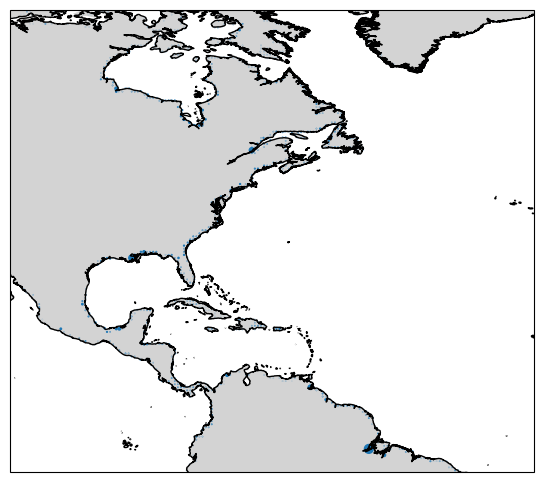

In [113]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy

# Choose a variable and time step to plot
data = river_nutrients['dic_riv_flux'].isel(time=0)
# Mask values <= 0
data_masked = data.where(data > 0)
lon_2d, lat_2d = np.meshgrid(data_masked.lon, data_masked.lat)

# Create a map plot
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot data
ax.scatter(lon_2d,lat_2d, s=data_masked.load(), transform=ccrs.PlateCarree())

# Add coastlines and features
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

# Set extent if desired (optional)
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())

plt.show()

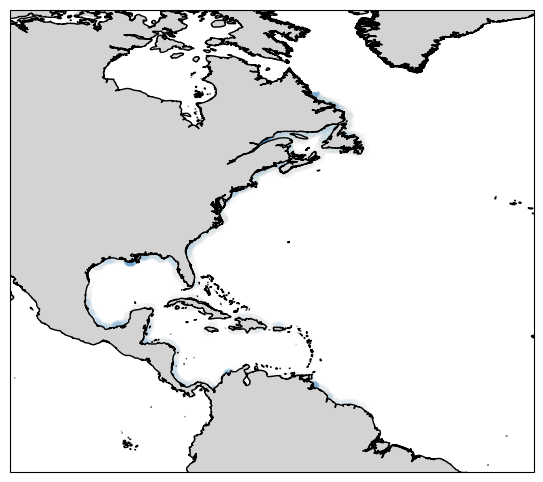

In [69]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy

# Choose a variable and time step to plot
data = river_nutrients_remapped['dic_riv_flux'].isel(time=0)
# Mask values <= 0
data_masked = data.where(data > 0)

# Create a map plot
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot data
ax.scatter(nwa_grid_t_points.x,nwa_grid_t_points.y, s=data_masked.load(), transform=ccrs.PlateCarree())

# Add coastlines and features



ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

# Set extent if desired (optional)
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())

plt.show()

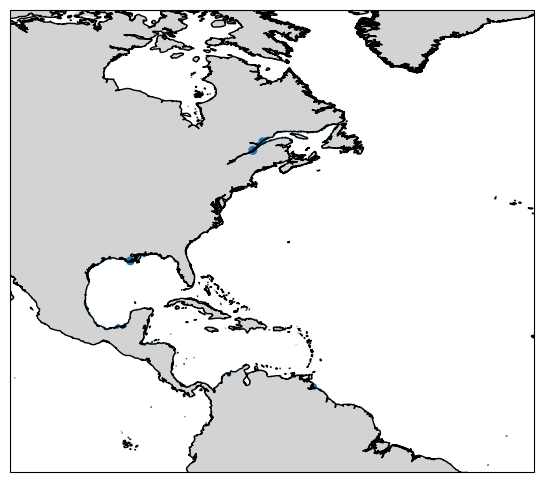

In [68]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy

# Choose a variable and time step to plot
data = river_nutrients_remapped_nn['dic_riv_flux'].isel(time=0)
# Mask values <= 0
data_masked = data.where(data > 0)

# Create a map plot
fig, ax = plt.subplots(figsize=(10,6), subplot_kw={'projection': ccrs.PlateCarree()})

# Plot data
ax.scatter(nwa_grid_t_points.x,nwa_grid_t_points.y, s=data_masked.load()*100, transform=ccrs.PlateCarree())

# Add coastlines and features



ax.add_feature(cartopy.feature.LAND, fc='lightgray')
ax.coastlines(resolution='10m')  # looks better with resolution='10m'

# Set extent if desired (optional)
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())

plt.show()

In [70]:
fill_value = -1e20
river_nutrients_remapped.to_netcdf(
    "river_nutrients_remapped.nc",
    encoding={var: {"_FillValue": fill_value} for var in river_nutrients_remapped.data_vars})


In [71]:
fill_value = -1e20
river_nutrients_remapped_nn.to_netcdf(
    "river_nutrients_remapped_nn.nc",
    encoding={var: {"_FillValue": fill_value} for var in river_nutrients_remapped_nn.data_vars})
